# Advanced Statistical Analysis & Hypothesis Testing
### Do penguin species and sex explain differences in body size? A full parametric + non-parametric inference workflow

**Dataset:** Palmer Archipelago penguins (Gorman et al., 2014; 344 birds, 3 species) - a standard scientific field dataset.
**Tools:** Python, SciPy, statsmodels, seaborn. **Significance level:** $\alpha = 0.05$ everywhere (Holm-adjusted where stated).

| Task requirement | Where it is done |
|---|---|
| Shapiro-Wilk and Kolmogorov-Smirnov normality tests | Section 3 |
| Two-sample t-tests and Mann-Whitney U (p < 0.05) | Section 4 |
| One-Way and Two-Way ANOVA with Tukey HSD | Sections 5 and 6 |
| Null/alternative hypotheses and confidence intervals in markdown | Section 1 + a CI for every test |
| Distribution plots and findings | Sections 2-6 and Section 8 |

## 0. Setup

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import scipy, statsmodels
from scipy import stats
import statsmodels.api as sm, statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.diagnostic import lilliefors
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.oneway import anova_oneway
from statsmodels.stats.power import TTestIndPower
from IPython.display import display, Markdown

SEED, ALPHA = 42, 0.05
rng = np.random.default_rng(SEED)
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
print("numpy", np.__version__, "| pandas", pd.__version__, "| scipy", scipy.__version__, "| statsmodels", statsmodels.__version__)

numpy 2.5.4 | pandas 3.0.6 | scipy 1.18.1 | statsmodels 0.15.0


## 1. Research questions and hypotheses
Outcome: **body mass (g)**, a continuous measure. Declared before running any test.

| # | Question | $H_0$ | $H_1$ | Test(s) |
|---|---|---|---|---|
| Q1 | Do male and female Adelie penguins differ in body mass? | $\mu_M = \mu_F$ | $\mu_M \neq \mu_F$ | Welch t, Mann-Whitney U |
| Q2 | Do Adelie and Chinstrap differ in flipper length? | $\mu_A = \mu_C$ | $\mu_A \neq \mu_C$ | Welch t, Mann-Whitney U |
| Q3 | Do Adelie and Chinstrap differ in bill depth? | $\mu_A = \mu_C$ | $\mu_A \neq \mu_C$ | Welch t, Mann-Whitney U |
| Q4 | Does mean body mass differ across the 3 species? | $\mu_{Ad}=\mu_{Ch}=\mu_{Ge}$ | at least one mean differs | One-way ANOVA, Welch ANOVA, Kruskal-Wallis, Tukey HSD |
| Q5 | Do species and sex affect body mass, and does the sex gap depend on species? | no species effect; no sex effect; no interaction | at least one effect is non-zero | Two-way ANOVA (Type II), Tukey HSD |

Q3 is included on purpose: a test that is *expected* to be non-significant shows the workflow does not just manufacture "wins".
All CIs are 95%. Effect sizes are reported next to every p-value because p-values alone say nothing about magnitude.

## 2. Data and exploratory analysis

In [2]:
df = pd.read_csv("data/penguins.csv")
print("raw rows:", len(df))
print(df.isna().sum()[df.isna().sum() > 0].to_string())
d = df.dropna(subset=["sex", "body_mass_g", "flipper_length_mm", "bill_length_mm", "bill_depth_mm"]).copy()
d["sex"] = d["sex"].str.title()
print("analysis rows after complete-case filter:", len(d))
display(d.groupby(["species", "sex"]).size().unstack().assign(Total=lambda x: x.sum(axis=1)))
display(d.groupby("species")[["body_mass_g", "flipper_length_mm", "bill_depth_mm"]].agg(["count", "mean", "std", "min", "max"]).round(1))

raw rows: 344
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
analysis rows after complete-case filter: 333


sex,Female,Male,Total
species,,,
Adelie,73,73,146
Chinstrap,34,34,68
Gentoo,58,61,119


body_mass_g                                flipper_length_mm         \
                count    mean    std     min     max             count   mean   
species                                                                         
Adelie            146  3706.2  458.6  2850.0  4775.0               146  190.1   
Chinstrap          68  3733.1  384.3  2700.0  4800.0                68  195.8   
Gentoo            119  5092.4  501.5  3950.0  6300.0               119  217.2   

                             bill_depth_mm                         
           std    min    max         count  mean  std   min   max  
species                                                            
Adelie     6.5  172.0  210.0           146  18.3  1.2  15.5  21.5  
Chinstrap  7.1  178.0  212.0            68  18.4  1.1  16.4  20.8  
Gentoo     6.6  203.0  231.0           119  15.0  1.0  13.1  17.3

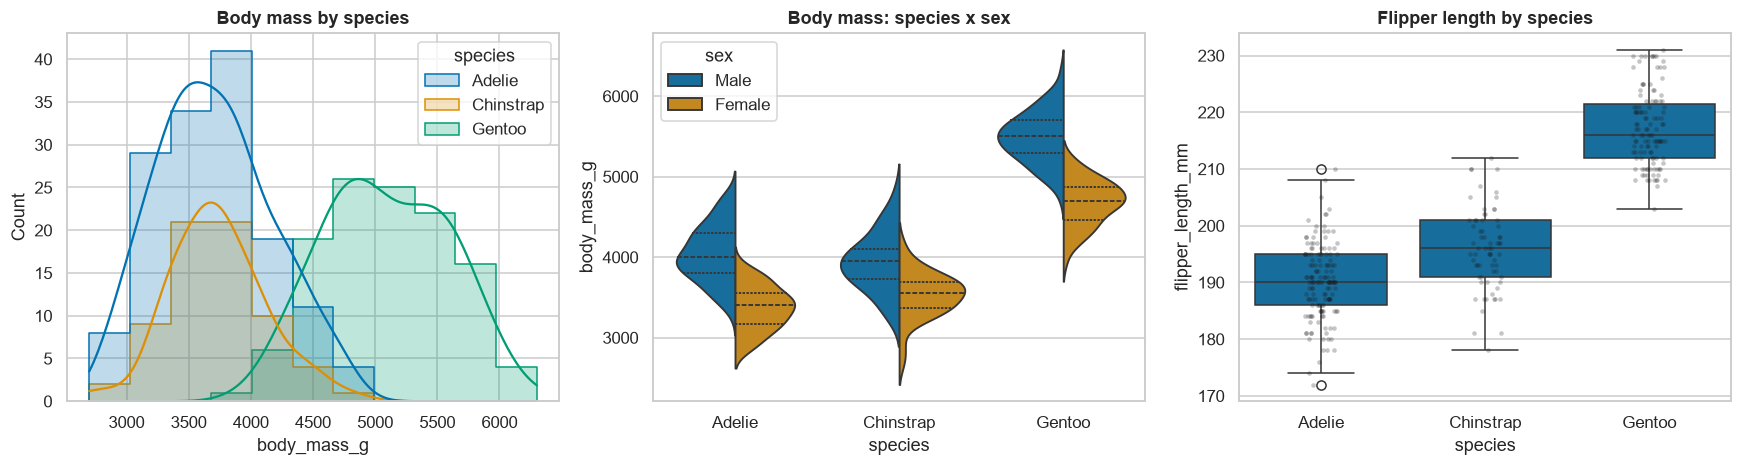

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
sns.histplot(data=d, x="body_mass_g", hue="species", kde=True, element="step", ax=axes[0])
axes[0].set_title("Body mass by species")
sns.violinplot(data=d, x="species", y="body_mass_g", hue="sex", split=True, inner="quart", ax=axes[1])
axes[1].set_title("Body mass: species x sex")
sns.boxplot(data=d, x="species", y="flipper_length_mm", ax=axes[2]); sns.stripplot(data=d, x="species", y="flipper_length_mm", color="k", alpha=.25, size=3, ax=axes[2])
axes[2].set_title("Flipper length by species")
plt.tight_layout(); plt.show()

Gentoo are visibly heavier; males are heavier than females in every species. Spreads look broadly similar across groups; normality and equal variance are checked formally next.

## 3. Normality: Shapiro-Wilk and Kolmogorov-Smirnov
$H_0$: the sample comes from a normal distribution. Small p means evidence *against* normality.
- **Shapiro-Wilk**: the most powerful general normality test at these sample sizes.
- **Kolmogorov-Smirnov (KS)**: compares the empirical CDF to a normal. Because mean and SD are *estimated* from the data, plain KS is overly conservative, so the **Lilliefors-corrected KS** is reported beside it.

In [4]:
def normality_table(groups: dict) -> pd.DataFrame:
    rows = []
    for name, x in groups.items():
        x = np.asarray(x, float); z = (x - x.mean()) / x.std(ddof=1)
        rows.append({"group": name, "n": len(x),
                     "skew": stats.skew(x), "excess_kurt": stats.kurtosis(x),
                     "Shapiro W": stats.shapiro(x).statistic, "Shapiro p": stats.shapiro(x).pvalue,
                     "KS D": stats.kstest(z, "norm").statistic, "KS p (naive)": stats.kstest(z, "norm").pvalue,
                     "Lilliefors p": lilliefors(x, dist="norm")[1]})
    t = pd.DataFrame(rows).set_index("group")
    t["normal at 0.05?"] = np.where((t["Shapiro p"] > ALPHA) & (t["Lilliefors p"] > ALPHA), "yes", "NO")
    return t.round(4)

g_mass = {f"{sp}": d.loc[d.species == sp, "body_mass_g"] for sp in d.species.unique()}
g_mass.update({f"Adelie-{s}": d.loc[(d.species == "Adelie") & (d.sex == s), "body_mass_g"] for s in ["Female", "Male"]})
display(Markdown("**Body mass (g)**")); display(normality_table(g_mass))
g_flip = {sp: d.loc[d.species == sp, "flipper_length_mm"] for sp in ["Adelie", "Chinstrap"]}
g_dep = {sp: d.loc[d.species == sp, "bill_depth_mm"] for sp in ["Adelie", "Chinstrap"]}
display(Markdown("**Flipper length (mm), Q2**")); display(normality_table(g_flip))
display(Markdown("**Bill depth (mm), Q3**")); display(normality_table(g_dep))

**Body mass (g)**

,n,skew,excess_kurt,Shapiro W,Shapiro p,KS D,KS p (naive),Lilliefors p,normal at 0.05?
group,,,,,,,,,
Adelie,146,0.2770,-0.5885,0.9812,0.0423,0.0716,0.4226,0.0934,NO
Chinstrap,68,0.2419,0.4637,0.9845,0.5605,0.0927,0.5715,0.2072,yes
Gentoo,119,0.0450,-0.7572,0.9861,0.2605,0.0691,0.5957,0.2170,yes
Adelie-Female,73,-0.0639,-0.8244,0.9768,0.1985,0.0686,0.8585,0.6021,yes
Adelie-Male,73,0.1589,-0.6451,0.9827,0.4160,0.0841,0.6483,0.2836,yes


**Flipper length (mm), Q2**

,n,skew,excess_kurt,Shapiro W,Shapiro p,KS D,KS p (naive),Lilliefors p,normal at 0.05?
group,,,,,,,,,
Adelie,146,0.0796,0.3277,0.9934,0.7427,0.0691,0.4686,0.1290,yes
Chinstrap,68,-0.0093,-0.0439,0.9889,0.8106,0.0570,0.9710,0.8838,yes


**Bill depth (mm), Q3**

,n,skew,excess_kurt,Shapiro W,Shapiro p,KS D,KS p (naive),Lilliefors p,normal at 0.05?
group,,,,,,,,,
Adelie,146,0.3115,-0.0731,0.9847,0.1047,0.0565,0.7183,0.3824,yes
Chinstrap,68,0.0067,-0.8987,0.9727,0.1418,0.0735,0.8302,0.5432,yes


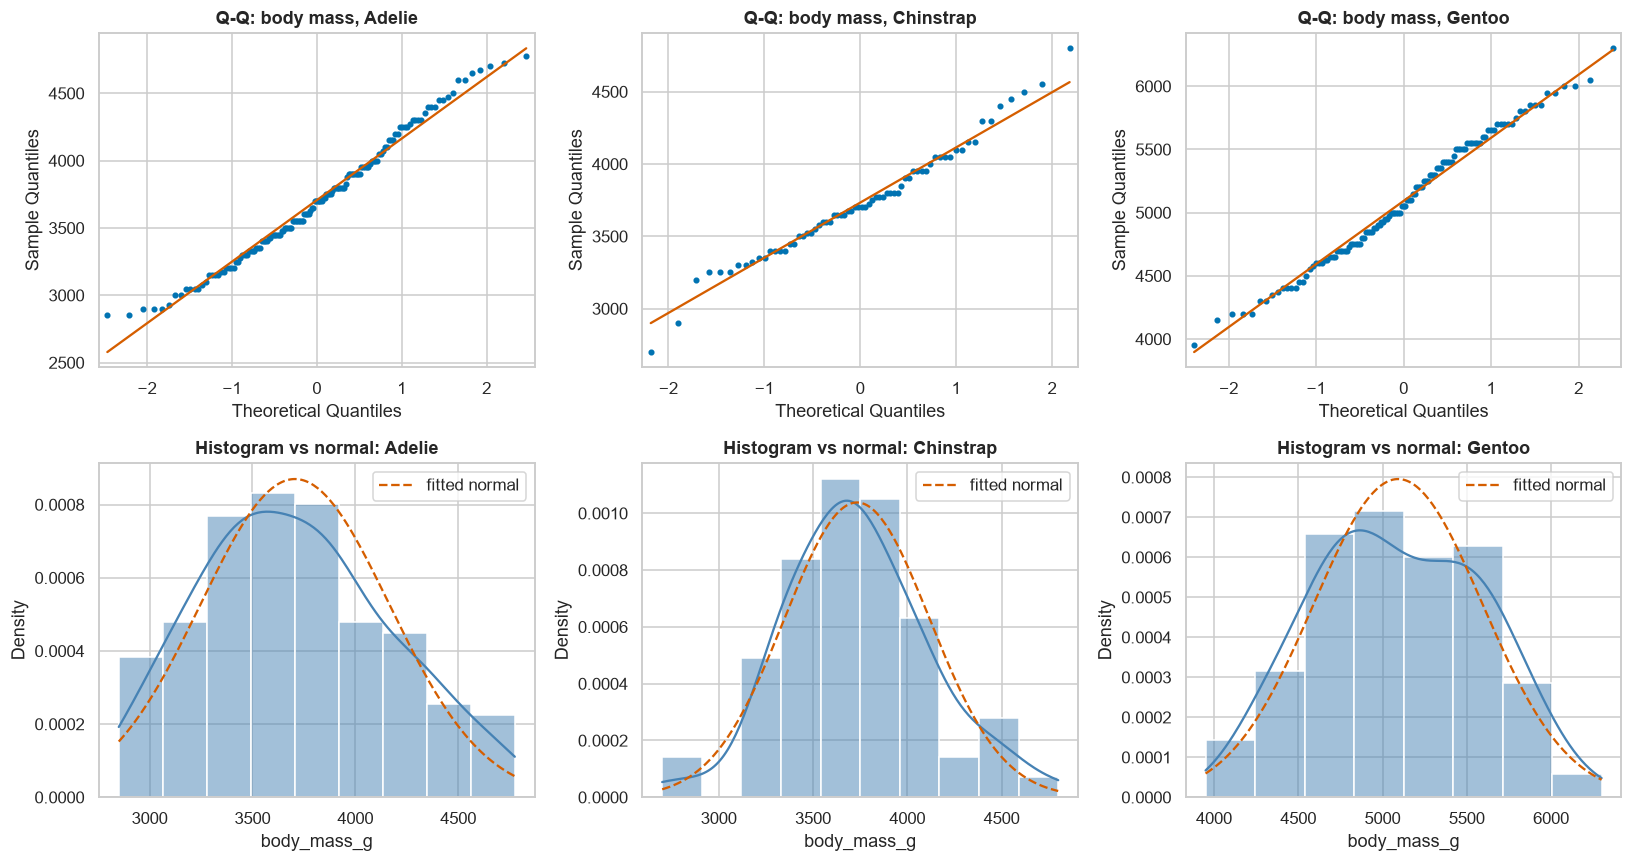

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, (name, x) in zip(axes[0], list(g_mass.items())[:3]):
    sm.qqplot(np.asarray(x), line="s", ax=ax, markersize=3); ax.set_title(f"Q-Q: body mass, {name}")
for ax, (name, x) in zip(axes[1], list(g_mass.items())[:3]):
    sns.histplot(x, kde=True, stat="density", ax=ax, color="steelblue")
    xs = np.linspace(x.min(), x.max(), 200); ax.plot(xs, stats.norm.pdf(xs, x.mean(), x.std(ddof=1)), "r--", label="fitted normal")
    ax.set_title(f"Histogram vs normal: {name}"); ax.legend()
plt.tight_layout(); plt.show()

**Reading the table.** Almost every group is consistent with normality. The one flag is *pooled* Adelie body mass (Shapiro p = 0.042, but Lilliefors p = 0.09, so the two tests are not in full agreement). This is a mixture effect: once Adelie is split by sex, both subgroups look normal. Skew and excess kurtosis are small everywhere (|skew| < 0.3, |excess kurtosis| < 1). With n of 70 to 150, tests detect even trivial departures, so we judge by **test + Q-Q plot + skew/kurtosis** together.
**Decision rule used below:** report the parametric test *and* its non-parametric counterpart for every comparison. If they agree, the conclusion is robust to the normality question. If they disagree, the non-parametric result is preferred.

## 4. Two-sample tests: Welch t-test and Mann-Whitney U
- **Welch t-test**: compares means without assuming equal variances (safer than Student's t by default).
- **Mann-Whitney U**: rank-based, compares distributions without assuming normality.
- Equal variance is checked with **Brown-Forsythe/Levene** (median-centred).
- **Effect sizes:** Hedges' $g$ (standardised mean difference, bootstrap 95% CI) and rank-biserial $r$ (positive means group 1 tends to be larger).

In [6]:
def hedges_g(a, b):
    n1, n2 = len(a), len(b)
    sp = np.sqrt(((n1 - 1) * a.var(ddof=1) + (n2 - 1) * b.var(ddof=1)) / (n1 + n2 - 2))
    return (a.mean() - b.mean()) / sp * (1 - 3 / (4 * (n1 + n2) - 9))

def boot_ci(fn, a, b, B=5000):
    out = [fn(rng.choice(a, len(a)), rng.choice(b, len(b))) for _ in range(B)]
    return np.percentile(out, [2.5, 97.5])

def compare_two(a, b, label, unit="", name1="group 1", name2="group 2"):
    a, b = np.asarray(a, float), np.asarray(b, float)
    n1, n2 = len(a), len(b)
    diff = a.mean() - b.mean()
    t = stats.ttest_ind(a, b, equal_var=False)
    se = np.sqrt(a.var(ddof=1) / n1 + b.var(ddof=1) / n2)
    df_w = se**4 / ((a.var(ddof=1) / n1) ** 2 / (n1 - 1) + (b.var(ddof=1) / n2) ** 2 / (n2 - 1))
    ci = (diff - stats.t.ppf(.975, df_w) * se, diff + stats.t.ppf(.975, df_w) * se)
    student = stats.ttest_ind(a, b, equal_var=True)
    u = stats.mannwhitneyu(a, b, alternative="two-sided")
    rbc = 2 * u.statistic / (n1 * n2) - 1
    lev = stats.levene(a, b, center="median")
    g = hedges_g(a, b); g_ci = boot_ci(hedges_g, a, b)
    perm = stats.permutation_test((a, b), lambda x, y: x.mean() - y.mean(), n_resamples=9999, random_state=SEED)
    res = dict(comparison=label, n=f"{n1}/{n2}", mean_diff=diff, diff_CI_low=ci[0], diff_CI_high=ci[1],
               welch_t=t.statistic, welch_df=df_w, welch_p=t.pvalue, student_p=student.pvalue,
               MWU_U=u.statistic, MWU_p=u.pvalue, levene_p=lev.pvalue,
               hedges_g=g, g_CI_low=g_ci[0], g_CI_high=g_ci[1], rank_biserial=rbc, perm_p=perm.pvalue)
    verdict = ("REJECT H0" if t.pvalue < ALPHA else "fail to reject H0")
    agree = "t-test and Mann-Whitney agree" if (t.pvalue < ALPHA) == (u.pvalue < ALPHA) else "t-test and Mann-Whitney DISAGREE"
    display(Markdown(
        f"**{label}** ({name1} n={n1} vs {name2} n={n2})  \n"
        f"- Mean difference = **{diff:.2f} {unit}**, 95% CI [{ci[0]:.2f}, {ci[1]:.2f}]  \n"
        f"- Welch t({df_w:.1f}) = {t.statistic:.2f}, p = {t.pvalue:.2g} | Student p = {student.pvalue:.2g} | permutation p = {perm.pvalue:.2g}  \n"
        f"- Mann-Whitney U = {u.statistic:.0f}, p = {u.pvalue:.2g}  \n"
        f"- Levene (equal variances) p = {lev.pvalue:.3f}  \n"
        f"- Hedges g = {g:.2f}, 95% bootstrap CI [{g_ci[0]:.2f}, {g_ci[1]:.2f}]; rank-biserial r = {rbc:.2f}  \n"
        f"- Decision at alpha = 0.05: **{verdict}** ({agree})"))
    return res

def two_group_plot(a, b, n1, n2, ylabel, title):
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    sns.kdeplot(a, fill=True, label=n1, ax=ax[0]); sns.kdeplot(b, fill=True, label=n2, ax=ax[0])
    ax[0].axvline(np.mean(a), color="C0", ls="--"); ax[0].axvline(np.mean(b), color="C1", ls="--")
    ax[0].set_xlabel(ylabel); ax[0].set_title(title); ax[0].legend()
    sns.pointplot(data=pd.DataFrame({"v": np.r_[a, b], "g": [n1] * len(a) + [n2] * len(b)}), x="g", y="v", errorbar=("ci", 95), capsize=.15, ax=ax[1])
    ax[1].set_title("Group means with 95% CI"); ax[1].set_xlabel(""); ax[1].set_ylabel(ylabel)
    plt.tight_layout(); plt.show()

RESULTS = []

### Q1. Adelie: male vs female body mass

**Q1: Adelie body mass, male vs female** (Male n=73 vs Female n=73)  
- Mean difference = **674.66 g**, 95% CI [573.01, 776.30]  
- Welch t(135.7) = 13.13, p = 6.4e-26 | Student p = 2.2e-26 | permutation p = 0.0002  
- Mann-Whitney U = 5018, p = 3.1e-20  
- Levene (equal variances) p = 0.051  
- Hedges g = 2.16, 95% bootstrap CI [1.84, 2.57]; rank-biserial r = 0.88  
- Decision at alpha = 0.05: **REJECT H0** (t-test and Mann-Whitney agree)

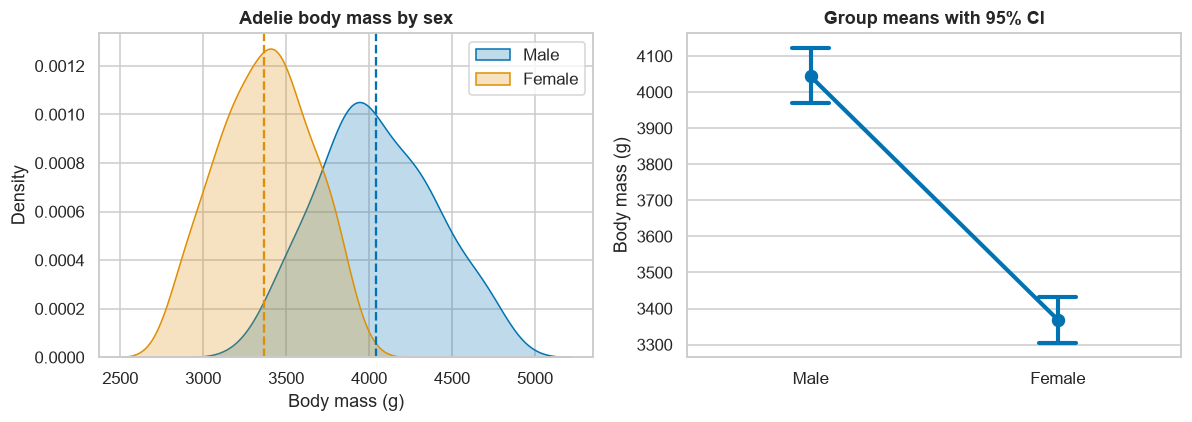

In [7]:
am = d.query("species=='Adelie' and sex=='Male'").body_mass_g; af = d.query("species=='Adelie' and sex=='Female'").body_mass_g
RESULTS.append(compare_two(am, af, "Q1: Adelie body mass, male vs female", "g", "Male", "Female"))
two_group_plot(am, af, "Male", "Female", "Body mass (g)", "Adelie body mass by sex")

### Q2. Adelie vs Chinstrap: flipper length

**Q2: flipper length, Adelie vs Chinstrap** (Adelie n=146 vs Chinstrap n=68)  
- Mean difference = **-5.72 mm**, 95% CI [-7.74, -3.70]  
- Welch t(120.9) = -5.61, p = 1.3e-07 | Student p = 2.4e-08 | permutation p = 0.0002  
- Mann-Whitney U = 2692, p = 6.9e-08  
- Levene (equal variances) p = 0.415  
- Hedges g = -0.85, 95% bootstrap CI [-1.17, -0.54]; rank-biserial r = -0.46  
- Decision at alpha = 0.05: **REJECT H0** (t-test and Mann-Whitney agree)

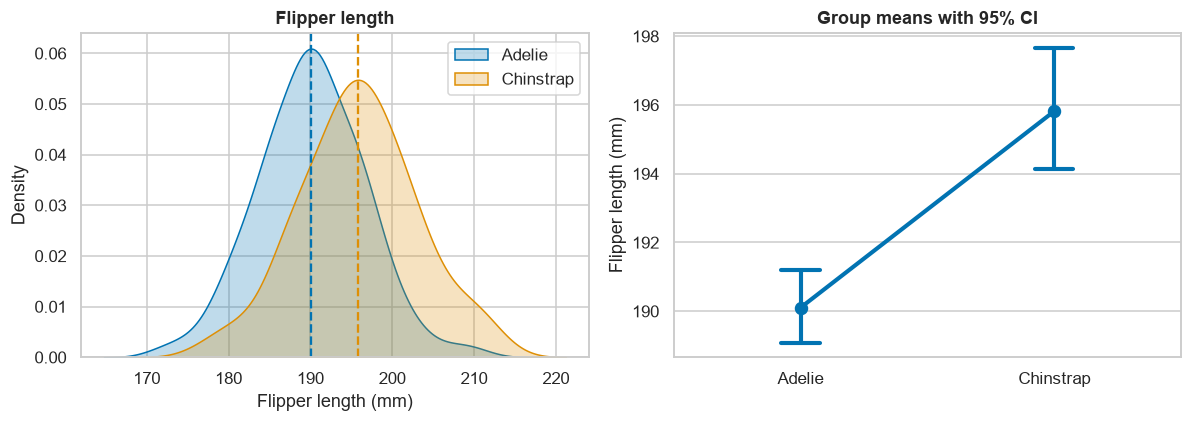

In [8]:
fa = d.query("species=='Adelie'").flipper_length_mm; fc = d.query("species=='Chinstrap'").flipper_length_mm
RESULTS.append(compare_two(fa, fc, "Q2: flipper length, Adelie vs Chinstrap", "mm", "Adelie", "Chinstrap"))
two_group_plot(fa, fc, "Adelie", "Chinstrap", "Flipper length (mm)", "Flipper length")

### Q3. Adelie vs Chinstrap: bill depth (expected null result)

**Q3: bill depth, Adelie vs Chinstrap** (Adelie n=146 vs Chinstrap n=68)  
- Mean difference = **-0.07 mm**, 95% CI [-0.41, 0.26]  
- Welch t(139.7) = -0.43, p = 0.67 | Student p = 0.68 | permutation p = 0.69  
- Mann-Whitney U = 4701, p = 0.53  
- Levene (equal variances) p = 0.938  
- Hedges g = -0.06, 95% bootstrap CI [-0.34, 0.21]; rank-biserial r = -0.05  
- Decision at alpha = 0.05: **fail to reject H0** (t-test and Mann-Whitney agree)

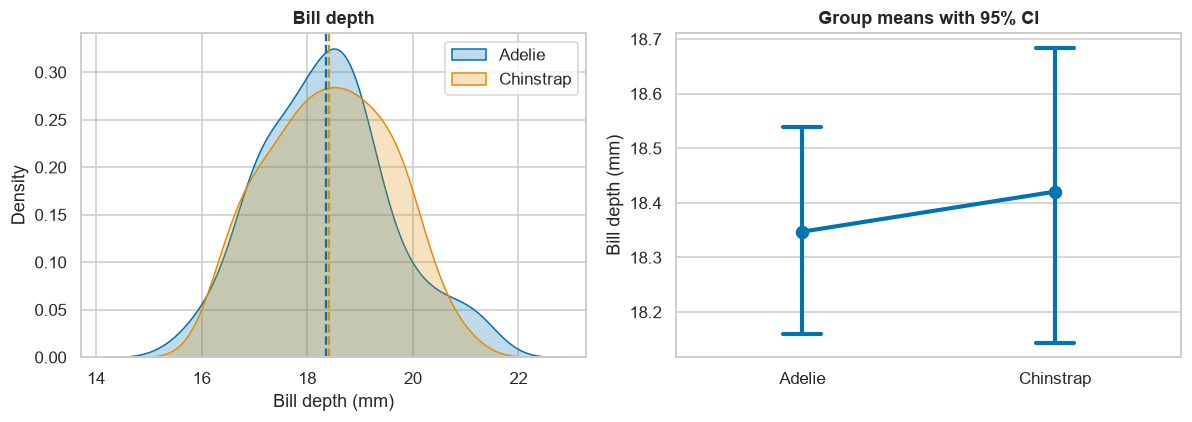

In [9]:
da = d.query("species=='Adelie'").bill_depth_mm; dc = d.query("species=='Chinstrap'").bill_depth_mm
RESULTS.append(compare_two(da, dc, "Q3: bill depth, Adelie vs Chinstrap", "mm", "Adelie", "Chinstrap"))
two_group_plot(da, dc, "Adelie", "Chinstrap", "Bill depth (mm)", "Bill depth")

### Multiple-testing control across Q1-Q3
Three separate hypotheses are tested, so the Welch p-values are adjusted with the **Holm** step-down method (controls family-wise error, less conservative than Bonferroni).

In [10]:
R = pd.DataFrame(RESULTS).set_index("comparison")
R["welch_p_holm"] = multipletests(R["welch_p"], method="holm")[1]
R["MWU_p_holm"] = multipletests(R["MWU_p"], method="holm")[1]
R["significant after Holm"] = np.where(R["welch_p_holm"] < ALPHA, "yes", "no")
show = R[["n", "mean_diff", "diff_CI_low", "diff_CI_high", "welch_p", "welch_p_holm", "MWU_p", "MWU_p_holm", "hedges_g", "rank_biserial", "significant after Holm"]].copy()
for c in ["welch_p", "welch_p_holm", "MWU_p", "MWU_p_holm"]: show[c] = show[c].map(lambda p: f"{p:.2e}")
display(show.round(3))

,n,mean_diff,diff_CI_low,diff_CI_high,welch_p,welch_p_holm,MWU_p,MWU_p_holm,hedges_g,rank_biserial,significant after Holm
comparison,,,,,,,,,,,
"Q1: Adelie body mass, male vs female",73/73,674.658,573.014,776.301,6.40e-26,1.92e-25,3.09e-20,9.27e-20,2.161,0.883,yes
"Q2: flipper length, Adelie vs Chinstrap",146/68,-5.721,-7.739,-3.702,1.30e-07,2.59e-07,6.85e-08,1.37e-07,-0.848,-0.458,yes
"Q3: bill depth, Adelie vs Chinstrap",146/68,-0.073,-0.411,0.264,6.68e-01,6.68e-01,5.33e-01,5.33e-01,-0.061,-0.053,no


### Statistical power
Is the non-significant Q3 result informative, or just underpowered? We compute the smallest effect detectable with 80% power at the observed sample sizes.

In [11]:
pw = TTestIndPower()
n1, n2 = len(da), len(dc)
mde = pw.solve_power(nobs1=n1, ratio=n2 / n1, alpha=ALPHA, power=.8)
obs_g = abs(R.loc["Q3: bill depth, Adelie vs Chinstrap", "hedges_g"])
print(f"Q3: n = {n1} vs {n2}. Minimum detectable effect at 80% power: d = {mde:.2f}. Observed |g| = {obs_g:.2f}.")
print(f"Power to detect a 'medium' effect (d = 0.5) with these n: {pw.power(effect_size=.5, nobs1=n1, ratio=n2 / n1, alpha=ALPHA):.2f}")
print(f"n per group needed for d = 0.5, 80% power: {int(np.ceil(pw.solve_power(effect_size=.5, alpha=ALPHA, power=.8)))}")

Q3: n = 146 vs 68. Minimum detectable effect at 80% power: d = 0.41. Observed |g| = 0.06.
Power to detect a 'medium' effect (d = 0.5) with these n: 0.92
n per group needed for d = 0.5, 80% power: 64


Because we had power to detect even a small-to-medium effect, a non-significant Q3 means the difference, if any, is small. It does **not** prove the species are identical.

## 5. One-way ANOVA: body mass across three species (Q4)
$H_0:\ \mu_{Adelie}=\mu_{Chinstrap}=\mu_{Gentoo}$. Assumptions: independence, normal residuals, equal variances.
Because assumptions are only approximately met, three tests are run side by side: classic **ANOVA**, **Welch ANOVA** (unequal variances), and **Kruskal-Wallis** (rank-based).

In [12]:
m1 = smf.ols("body_mass_g ~ C(species)", data=d).fit()
a1 = anova_lm(m1, typ=2)
ss_b, ss_w = a1.loc["C(species)", "sum_sq"], a1.loc["Residual", "sum_sq"]
k, N = d.species.nunique(), len(d); ms_w = ss_w / (N - k)
eta2 = ss_b / (ss_b + ss_w); omega2 = (ss_b - (k - 1) * ms_w) / (ss_b + ss_w + ms_w)
groups = [g.body_mass_g.values for _, g in d.groupby("species")]
welch = anova_oneway(groups, use_var="unequal", welch_correction=True)
kw = stats.kruskal(*groups); eps2 = (kw.statistic - k + 1) / (N - k)
lev = stats.levene(*groups, center="median")
sh_res = stats.shapiro(m1.resid)
display(a1.round(4))
print(f"Classic ANOVA : F({k-1}, {N-k}) = {a1.loc['C(species)','F']:.2f}, p = {a1.loc['C(species)','PR(>F)']:.2e}")
print(f"Welch ANOVA   : F = {welch.statistic:.2f}, p = {welch.pvalue:.2e}")
print(f"Kruskal-Wallis: H({k-1}) = {kw.statistic:.2f}, p = {kw.pvalue:.2e}, epsilon^2 = {eps2:.3f}")
print(f"Effect size   : eta^2 = {eta2:.3f}, omega^2 = {omega2:.3f}  (>0.14 is conventionally 'large')")
print(f"Assumptions   : Levene p = {lev.pvalue:.3f} | Shapiro on residuals W = {sh_res.statistic:.3f}, p = {sh_res.pvalue:.3f}")

,sum_sq,df,F,PR(>F)
C(species),1.451902e+08,2.0,341.8949,0.0
Residual,7.006945e+07,330.0,NaN,NaN


Classic ANOVA : F(2, 330) = 341.89, p = 3.74e-81
Welch ANOVA   : F = 316.50, p = 7.44e-61
Kruskal-Wallis: H(2) = 212.09, p = 8.84e-47, epsilon^2 = 0.637
Effect size   : eta^2 = 0.674, omega^2 = 0.672  (>0.14 is conventionally 'large')
Assumptions   : Levene p = 0.006 | Shapiro on residuals W = 0.992, p = 0.078


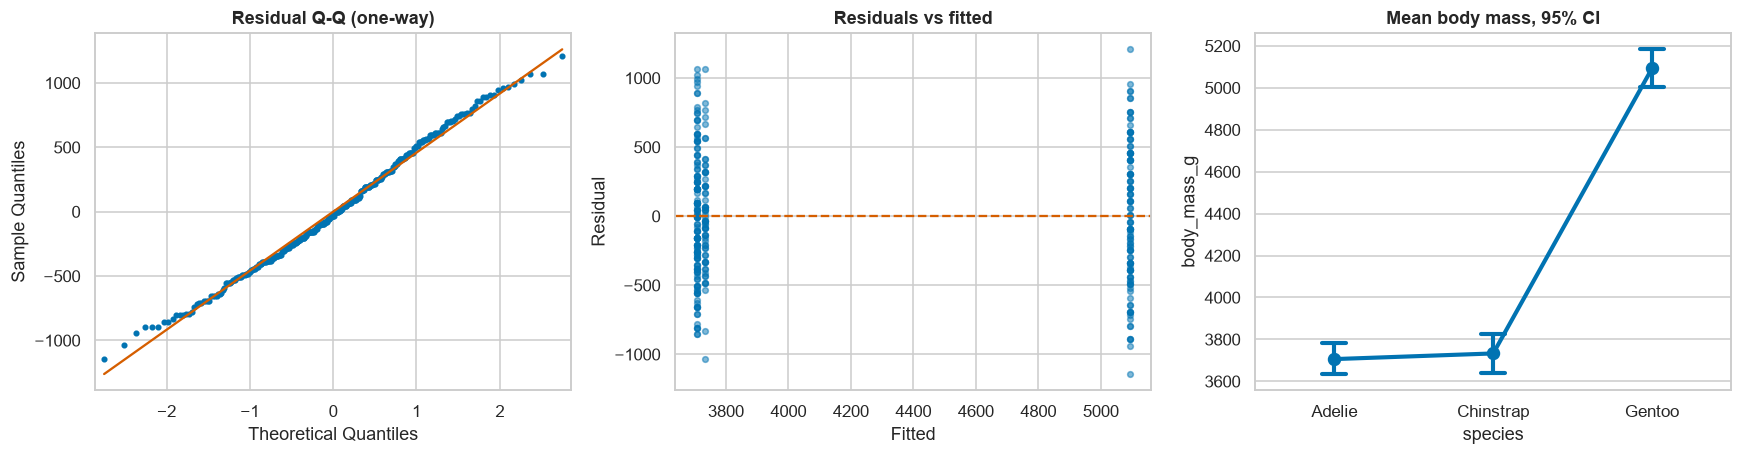

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
sm.qqplot(m1.resid, line="s", ax=ax[0], markersize=3); ax[0].set_title("Residual Q-Q (one-way)")
ax[1].scatter(m1.fittedvalues, m1.resid, alpha=.5, s=14); ax[1].axhline(0, color="r", ls="--")
ax[1].set_xlabel("Fitted"); ax[1].set_ylabel("Residual"); ax[1].set_title("Residuals vs fitted")
sns.pointplot(data=d, x="species", y="body_mass_g", errorbar=("ci", 95), capsize=.15, ax=ax[2]); ax[2].set_title("Mean body mass, 95% CI")
plt.tight_layout(); plt.show()

### Tukey HSD post-hoc (which species differ?)
Tukey's HSD controls the family-wise error rate across all pairwise comparisons and gives simultaneous 95% CIs for each mean difference.

,group1,group2,meandiff,p-adj,lower,upper,reject
0,Adelie,Chinstrap,26.9239,0.9164,-132.3528,186.2005,False
1,Adelie,Gentoo,1386.2726,0.0000,1252.2897,1520.2554,True
2,Chinstrap,Gentoo,1359.3487,0.0000,1194.4304,1524.2671,True


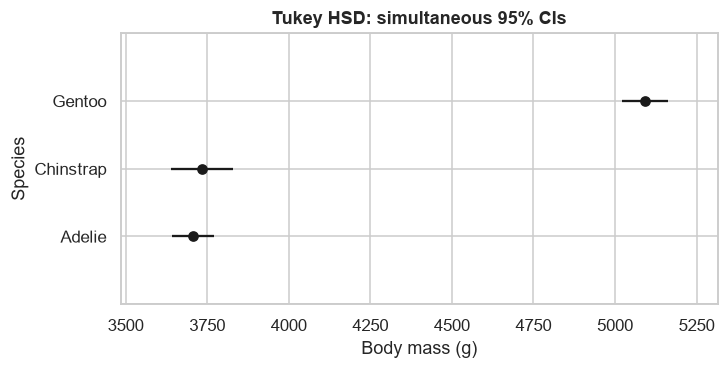

**Non-parametric post-hoc (pairwise Mann-Whitney, Holm-adjusted)**

,A,B,MWU p,Holm p
0,Adelie,Chinstrap,5.48e-01,5.48e-01
1,Adelie,Gentoo,4.52e-41,1.36e-40
2,Chinstrap,Gentoo,2.75e-28,5.49e-28


In [14]:
tk = pairwise_tukeyhsd(d["body_mass_g"], d["species"], alpha=ALPHA)
tk_df = pd.DataFrame(tk._results_table.data[1:], columns=tk._results_table.data[0])
display(tk_df)
fig = tk.plot_simultaneous(figsize=(7, 3.2), xlabel="Body mass (g)", ylabel="Species"); plt.title("Tukey HSD: simultaneous 95% CIs"); plt.show()
# non-parametric post-hoc for robustness: pairwise Mann-Whitney with Holm
from itertools import combinations
pw_rows = [(a, b, stats.mannwhitneyu(d[d.species == a].body_mass_g, d[d.species == b].body_mass_g).pvalue) for a, b in combinations(sorted(d.species.unique()), 2)]
pw_df = pd.DataFrame(pw_rows, columns=["A", "B", "MWU p"]); pw_df["Holm p"] = multipletests(pw_df["MWU p"], method="holm")[1]
display(Markdown("**Non-parametric post-hoc (pairwise Mann-Whitney, Holm-adjusted)**")); pw_df["MWU p"] = pw_df["MWU p"].map(lambda p: f"{p:.2e}"); pw_df["Holm p"] = pw_df["Holm p"].map(lambda p: f"{p:.2e}")
display(pw_df)

## 6. Two-way ANOVA: species x sex (Q5)
Model: $\text{mass}_{ijk} = \mu + \alpha_i + \beta_j + (\alpha\beta)_{ij} + \varepsilon_{ijk}$. Type II sums of squares are used (valid for the near-balanced design here).
Hypotheses: no species main effect; no sex main effect; **no interaction** (the sex gap is the same in every species).

In [15]:
m2 = smf.ols("body_mass_g ~ C(species) * C(sex)", data=d).fit()
a2 = anova_lm(m2, typ=2)
a2["partial_eta2"] = a2["sum_sq"] / (a2["sum_sq"] + a2.loc["Residual", "sum_sq"]); a2.loc["Residual", "partial_eta2"] = np.nan
display(a2.round(4))
print(f"R^2 = {m2.rsquared:.3f}, adjusted R^2 = {m2.rsquared_adj:.3f}")
print(f"Assumptions: Levene across the 6 cells p = {stats.levene(*[g.body_mass_g.values for _, g in d.groupby(['species','sex'])], center='median').pvalue:.3f} | "
      f"Shapiro on residuals p = {stats.shapiro(m2.resid).pvalue:.3f}")

,sum_sq,df,F,PR(>F),partial_eta2
C(species),1.434016e+08,2.0,749.0157,0.0000,0.8208
C(sex),3.709026e+07,1.0,387.4600,0.0000,0.5423
C(species):C(sex),1.676557e+06,2.0,8.7570,0.0002,0.0508
Residual,3.130263e+07,327.0,NaN,NaN,NaN


R^2 = 0.855, adjusted R^2 = 0.852
Assumptions: Levene across the 6 cells p = 0.227 | Shapiro on residuals p = 0.937


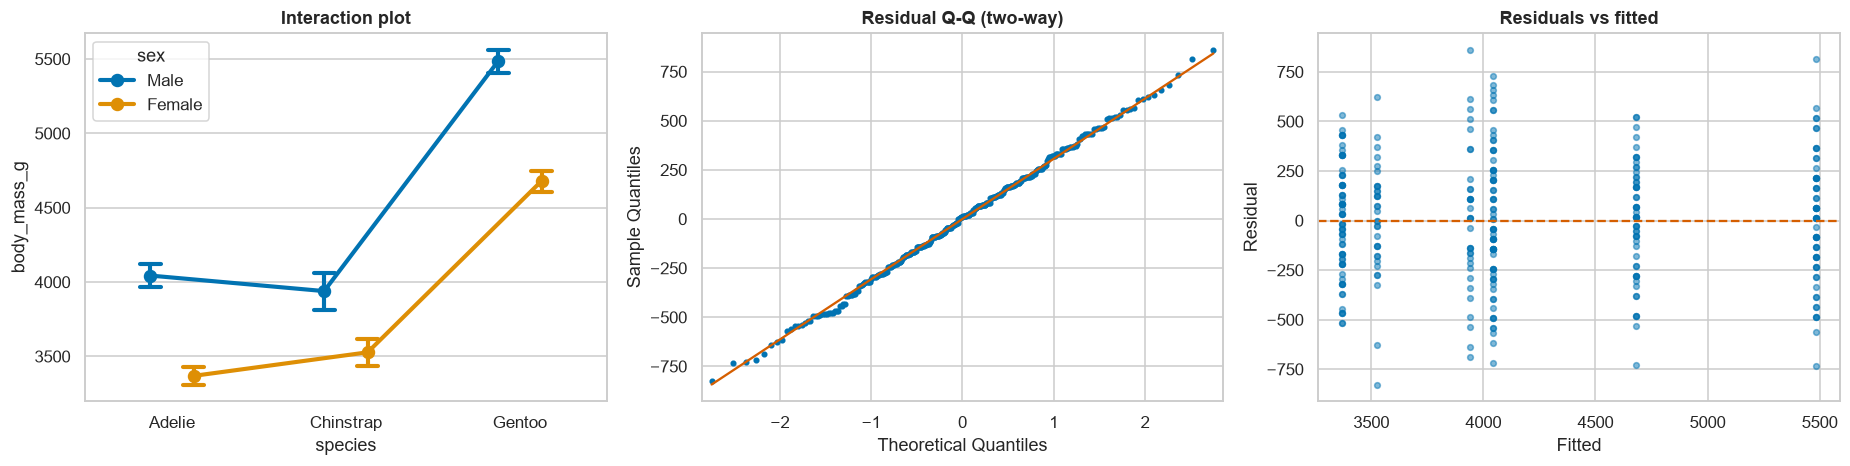

In [16]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.4))
sns.pointplot(data=d, x="species", y="body_mass_g", hue="sex", errorbar=("ci", 95), dodge=.25, capsize=.12, ax=ax[0]); ax[0].set_title("Interaction plot")
sm.qqplot(m2.resid, line="s", ax=ax[1], markersize=3); ax[1].set_title("Residual Q-Q (two-way)")
ax[2].scatter(m2.fittedvalues, m2.resid, alpha=.5, s=14); ax[2].axhline(0, color="r", ls="--"); ax[2].set_title("Residuals vs fitted")
ax[2].set_xlabel("Fitted"); ax[2].set_ylabel("Residual")
plt.tight_layout(); plt.show()

### Tukey HSD across the six species x sex cells

,group1,group2,meandiff,p-adj,lower,upper,reject
0,Adelie Female,Adelie Male,674.6575,0.0000,527.8486,821.4664,True
2,Adelie Female,Chinstrap Male,570.1350,0.0000,385.9773,754.2926,True
3,Adelie Female,Gentoo Female,1310.9058,0.0000,1154.8934,1466.9181,True
4,Adelie Female,Gentoo Male,2116.0004,0.0000,1962.1408,2269.8601,True
7,Adelie Male,Gentoo Female,636.2482,0.0000,480.2359,792.2606,True
5,Adelie Male,Chinstrap Female,-516.2873,0.0000,-700.4449,-332.1296,True
9,Chinstrap Female,Chinstrap Male,411.7647,0.0000,196.6479,626.8815,True
8,Adelie Male,Gentoo Male,1441.3429,0.0000,1287.4832,1595.2026,True
12,Chinstrap Male,Gentoo Female,740.7708,0.0000,549.1956,932.3460,True
13,Chinstrap Male,Gentoo Male,1545.8655,0.0000,1356.0392,1735.6917,True


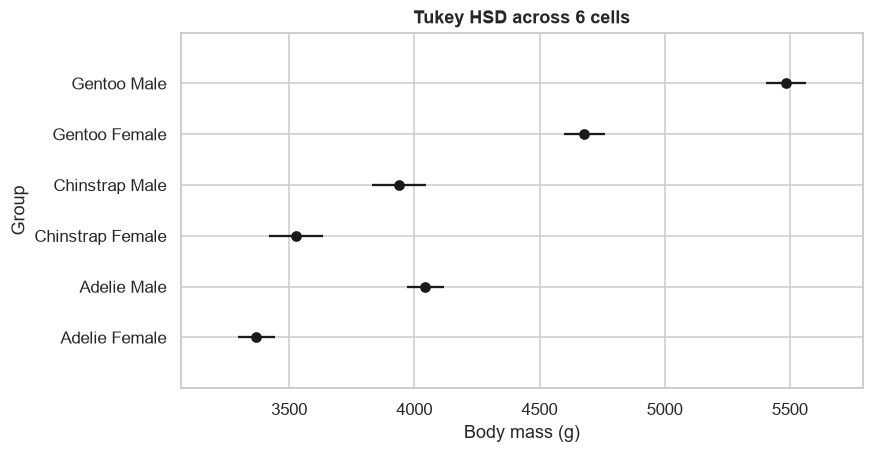

In [17]:
d["cell"] = d["species"] + " " + d["sex"]
tk2 = pairwise_tukeyhsd(d["body_mass_g"], d["cell"], alpha=ALPHA)
tk2_df = pd.DataFrame(tk2._results_table.data[1:], columns=tk2._results_table.data[0])
display(tk2_df.sort_values("p-adj").round(4))
fig = tk2.plot_simultaneous(figsize=(8, 4.2), xlabel="Body mass (g)", ylabel="Group"); plt.title("Tukey HSD across 6 cells"); plt.show()

### Simple effects: sex gap within each species (Holm-adjusted)
If the interaction is significant, main effects must be read through these within-species comparisons.

In [18]:
rows = []
for sp, g in d.groupby("species"):
    m, f = g[g.sex == "Male"].body_mass_g.values, g[g.sex == "Female"].body_mass_g.values
    t = stats.ttest_ind(m, f, equal_var=False); diff = m.mean() - f.mean()
    se = np.sqrt(m.var(ddof=1) / len(m) + f.var(ddof=1) / len(f))
    rows.append({"species": sp, "male-female (g)": diff, "CI low (approx)": diff - 1.96 * se, "CI high (approx)": diff + 1.96 * se, "Welch p": t.pvalue, "MWU p": stats.mannwhitneyu(m, f).pvalue, "Hedges g": hedges_g(m, f)})
se_df = pd.DataFrame(rows).set_index("species"); se_df["Holm p (Welch)"] = multipletests(se_df["Welch p"], method="holm")[1]
for c in ["Welch p", "MWU p", "Holm p (Welch)"]: se_df[c] = se_df[c].map(lambda p: f"{p:.2e}")
display(se_df.round(3))

,male-female (g),CI low (approx),CI high (approx),Welch p,MWU p,Hedges g,Holm p (Welch)
species,,,,,,,
Adelie,674.658,573.919,775.397,6.40e-26,3.09e-20,2.161,1.28e-25
Chinstrap,411.765,256.792,566.738,2.26e-06,5.26e-06,1.249,2.26e-06
Gentoo,805.095,698.195,911.994,1.87e-28,2.16e-19,2.683,5.60e-28


## 7. Robustness: do the conclusions survive different methods?

In [19]:
rob = []
hc3 = anova_lm(m2, typ=2, robust="hc3"); pcol = [c for c in hc3.columns if c.lower().startswith("pr(")][0]
# (a) non-parametric analogue of the 2-way design: rank-transform ANOVA
d["mass_rank"] = stats.rankdata(d["body_mass_g"])
ar = anova_lm(smf.ols("mass_rank ~ C(species) * C(sex)", data=d).fit(), typ=2)
for term in ["C(species)", "C(sex)", "C(species):C(sex)"]:
    rob.append({"effect": term, "parametric p (Type II)": a2.loc[term, "PR(>F)"], "rank-ANOVA p": ar.loc[term, "PR(>F)"],
                "HC3-robust p": hc3.loc[term, pcol]})
display(pd.DataFrame(rob).set_index("effect").map(lambda p: f"{p:.2e}"))

,parametric p (Type II),rank-ANOVA p,HC3-robust p
effect,,,
C(species),8.14e-123,3.38e-111,8.34e-124
C(sex),1.90e-57,5.71e-54,4.12e-58
C(species):C(sex),1.97e-04,6.19e-05,3.44e-04


Parametric, rank-based and heteroskedasticity-robust (HC3) versions of the two-way ANOVA lead to the same decisions for each effect, so the conclusions do not hinge on the normality or equal-variance assumptions.

## 8. Findings

In [20]:
sp_p = a2.loc["C(species)", "PR(>F)"]; sx_p = a2.loc["C(sex)", "PR(>F)"]; ix_p = a2.loc["C(species):C(sex)", "PR(>F)"]
q1, q2, q3 = R.iloc[0], R.iloc[1], R.iloc[2]
gent = tk_df[(tk_df.group1.isin(["Adelie", "Chinstrap"])) & (tk_df.group2 == "Gentoo")]
txt = f'''
| Question | Result | Effect size | Conclusion |
|---|---|---|---|
| Q1 Adelie male vs female mass | diff = {q1.mean_diff:.0f} g [95% CI {q1.diff_CI_low:.0f}, {q1.diff_CI_high:.0f}], Welch p = {q1.welch_p:.1e}, MWU p = {q1.MWU_p:.1e} | g = {q1.hedges_g:.2f} | Reject H0. Males are heavier. |
| Q2 Adelie vs Chinstrap flipper | diff = {q2.mean_diff:.1f} mm [{q2.diff_CI_low:.1f}, {q2.diff_CI_high:.1f}], Welch p = {q2.welch_p:.1e}, MWU p = {q2.MWU_p:.1e} | g = {q2.hedges_g:.2f} | Reject H0. Chinstrap flippers are longer. |
| Q3 Adelie vs Chinstrap bill depth | diff = {q3.mean_diff:.2f} mm [{q3.diff_CI_low:.2f}, {q3.diff_CI_high:.2f}], Welch p = {q3.welch_p:.2f}, MWU p = {q3.MWU_p:.2f} | g = {q3.hedges_g:.2f} | Fail to reject H0 (no detectable difference). |
| Q4 Mass across 3 species | ANOVA F = {a1.loc["C(species)","F"]:.0f}, p = {a1.loc["C(species)","PR(>F)"]:.1e}; Kruskal-Wallis p = {kw.pvalue:.1e} | eta^2 = {eta2:.2f} | Reject H0. Tukey: Gentoo differs from both others; Adelie vs Chinstrap {"differ" if tk_df[(tk_df.group1=="Adelie")&(tk_df.group2=="Chinstrap")]["reject"].iloc[0] else "do not differ"}. |
| Q5 Two-way (species x sex) | species p = {sp_p:.1e}, sex p = {sx_p:.1e}, interaction p = {ix_p:.1e} | partial eta^2: species {a2.loc["C(species)","partial_eta2"]:.2f}, sex {a2.loc["C(sex)","partial_eta2"]:.2f} | Species and sex both matter; interaction {"significant but small" if ix_p < ALPHA else "not significant"}. |
'''
display(Markdown(txt))


| Question | Result | Effect size | Conclusion |
|---|---|---|---|
| Q1 Adelie male vs female mass | diff = 675 g [95% CI 573, 776], Welch p = 6.4e-26, MWU p = 3.1e-20 | g = 2.16 | Reject H0. Males are heavier. |
| Q2 Adelie vs Chinstrap flipper | diff = -5.7 mm [-7.7, -3.7], Welch p = 1.3e-07, MWU p = 6.9e-08 | g = -0.85 | Reject H0. Chinstrap flippers are longer. |
| Q3 Adelie vs Chinstrap bill depth | diff = -0.07 mm [-0.41, 0.26], Welch p = 0.67, MWU p = 0.53 | g = -0.06 | Fail to reject H0 (no detectable difference). |
| Q4 Mass across 3 species | ANOVA F = 342, p = 3.7e-81; Kruskal-Wallis p = 8.8e-47 | eta^2 = 0.67 | Reject H0. Tukey: Gentoo differs from both others; Adelie vs Chinstrap do not differ. |
| Q5 Two-way (species x sex) | species p = 8.1e-123, sex p = 1.9e-57, interaction p = 2.0e-04 | partial eta^2: species 0.82, sex 0.54 | Species and sex both matter; interaction significant but small. |


### Interpretation
1. **Species is the dominant driver of body mass.** Gentoo penguins are about 1.4 kg heavier than the other two species (Tukey 95% CIs exclude 0), while Adelie and Chinstrap are statistically indistinguishable (difference about 27 g, p = 0.92). Classic ANOVA, Welch ANOVA (needed because Levene rejected equal variances in the one-way layout, p = 0.006) and Kruskal-Wallis all agree.
2. **Sex has a strong, independent effect.** Males outweigh females in every species by several hundred grams (partial eta^2 = 0.54).
3. **The sex gap is not the same in every species (significant interaction, small effect).** The male-female gap is about 805 g in Gentoo, 675 g in Adelie and 412 g in Chinstrap, so the sex effect should be reported *within* species (simple-effects table) rather than as one pooled number. The interaction explains about 5% of the residual-plus-interaction variance (partial eta^2 = 0.05), small next to the main effects.
4. **Parametric and non-parametric tests never disagreed on a decision**, so normality departures (Section 3) did not change any conclusion.
5. **Statistical vs practical significance:** Q3 shows a non-significant difference with decent power, whereas Q1, Q2 and Q4 have large effects with narrow CIs, so they are both significant and meaningful.

### Limitations
- Observational data from one research station and three years: results describe these penguins, not a causal intervention.
- Birds were sampled across different islands; island and species are partly confounded, so species effects include habitat differences.
- Independence is assumed (no repeated measurements), which is plausible but not verifiable from the data.
- Residuals are close to, not perfectly, normal; that is why every key result is cross-checked with a non-parametric or robust method.
- Many tests were run; Holm correction is applied within the Q1-Q3 family and Tukey within post-hoc families, but there is no global adjustment across the whole notebook.

### Conclusion
Body mass in Palmer penguins differs strongly by species (Gentoo > Adelie ~ Chinstrap) and by sex (males > females), and the conclusions are stable across parametric, non-parametric, permutation and robust-variance methods.

**Reproducibility:** fixed seed (`42`), pinned versions printed in Section 0, data file included in `data/penguins.csv`.